In [1]:
# Configuração do ambiente, importações de bibliotecas e carregamento de módulos do projeto

import sys
import os

# Adiciona o diretório pai (raiz do projeto) ao caminho do Python
sys.path.append(os.path.abspath(os.path.join('..')))

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from pathlib import Path

from src.experiments import build_optimizer, run_experiment, run_multiple_seeds, run_hyperparameter_experiment, run_interaction_experiment, run_random_search


from src.config import RANDOM_STATE
from src.models import MLP
from src.train import train_model
from src.data.torch_data import create_dataloaders
from src.utils.reproducibility import set_seed

In [2]:
# Carregamento dos conjuntos de dados pré-processados em formato TensorDataset (.pt)

PROCESSED_DIR = Path("../data/processed")

regression_datasets = torch.load(
    PROCESSED_DIR / "regression_data.pt",
    weights_only=False
)

classification_datasets = torch.load(
    PROCESSED_DIR / "classification_data.pt",
    weights_only=False
)

In [3]:
# Inspeção das divisões dos datasets (treino, validação e teste) para regressão e classificação

print("=== REGRESSÃO ===")

for split, dataset in regression_datasets.items():
    X, y = dataset.tensors
    print(f"{split}: X={X.shape}, y={y.shape}")


print("\n=== CLASSIFICAÇÃO ===")

for split, dataset in classification_datasets.items():
    X, y = dataset.tensors
    print(f"{split}: X={X.shape}, y={y.shape}")

=== REGRESSÃO ===
train: X=torch.Size([32000, 15]), y=torch.Size([32000, 1])
val: X=torch.Size([8000, 15]), y=torch.Size([8000, 1])
test: X=torch.Size([10000, 15]), y=torch.Size([10000, 1])

=== CLASSIFICAÇÃO ===
train: X=torch.Size([32000, 15]), y=torch.Size([32000])
val: X=torch.Size([8000, 15]), y=torch.Size([8000])
test: X=torch.Size([10000, 15]), y=torch.Size([10000])


In [4]:
# Carregamento do scaler ajustado do alvo de regressão (StandardScaler)

target_scaler = joblib.load(
    PROCESSED_DIR / "regression_target_scaler.pkl"
)

In [5]:
# Exibição dos parâmetros estatísticos do scaler do alvo (média e desvio padrão aprendidos)

print("Tipo do objeto:", type(target_scaler))
print("Média aprendida:", target_scaler.mean_)
print("Desvio padrão aprendido:", target_scaler.scale_)
print("Número de features:", target_scaler.n_features_in_)

Tipo do objeto: <class 'sklearn.preprocessing._data.StandardScaler'>
Média aprendida: [74.03228125]
Desvio padrão aprendido: [15.64329095]
Número de features: 1


In [5]:
# Definição da configuração baseline de referência e lista de sementes aleatórias fixas

BASELINE_CONFIG = {
    "hidden": (32, 32),
    "activation": "ReLU",
    "optimizer": "Adam",
    "lr": 0.001,
    "batch_size": 64,
    "epochs": 200,
    "patience": 20,
    "dropout": 0.0,
    "weight_decay": 0.0,
}

SEEDS = [42, 125, 400, 850, 2000]

In [7]:
# Instanciação e verificação da arquitetura MLP de referência para regressão

model = MLP(
    in_dim=15,
    out_dim=1,
    hidden=(32, 32),
    activation="ReLU",
    dropout=0.0
)

optimizer = build_optimizer(
    model=model,
    optimizer_name="Adam",
    lr=0.001
)

print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0
)


In [ ]:
# Execução de teste preliminar do pipeline de treino com baseline de regressão em semente única

result = run_experiment(
    datasets=regression_datasets,
    task="regression",
    config=BASELINE_CONFIG,
    seed=42,
    target_scaler=target_scaler,
)

print("Melhor época:", result["best_epoch"])
print("Parâmetros treináveis:", result["trainable_params"])
print("Tempo:", round(result["elapsed_time"], 2), "segundos")

print("RMSE treino:", result["train_metrics"]["rmse"])
print("RMSE validação:", result["val_metrics"]["rmse"])
print("Gap:", result["generalization_gap"])

In [ ]:
# Execução de teste preliminar do pipeline de treino com baseline de classificação em semente única

result_classification = run_experiment(
    datasets=classification_datasets,
    task="classification",
    config=BASELINE_CONFIG,
    seed=42,
)

print("Melhor época:", result_classification["best_epoch"])
print("F1 treino:", result_classification["train_metrics"]["f1_macro"])
print("F1 validação:", result_classification["val_metrics"]["f1_macro"])
print("Gap:", result_classification["generalization_gap"])

In [ ]:
# Treinamento do baseline de regressão sobre múltiplas sementes e cálculo de média e desvio padrão

reg_results, reg_df, reg_summary = run_multiple_seeds(
    datasets=regression_datasets,
    task="regression",
    config=BASELINE_CONFIG,
    seeds=SEEDS,
    target_scaler=target_scaler,
)

display(reg_df)
display(reg_summary)

In [ ]:
# Treinamento do baseline de classificação sobre múltiplas sementes e cálculo de média e desvio padrão

cls_results, cls_df, cls_summary = run_multiple_seeds(
    datasets=classification_datasets,
    task="classification",
    config=BASELINE_CONFIG,
    seeds=SEEDS,
)

display(cls_df)
display(cls_summary)

In [ ]:
# Definição da grade de valores testados para quantidade de neurônios por camada

NEURONS_VALUES = [2, 4, 8, 16, 32, 64, 128]

In [ ]:
# Execução dos experimentos variando o número de neurônios na regressão com múltiplas sementes

reg_neurons_results, reg_neurons_df, reg_neurons_summary = (
    run_hyperparameter_experiment(
        datasets=regression_datasets,
        task="regression",
        base_config=BASELINE_CONFIG,
        parameter="neurons",
        values=NEURONS_VALUES,
        seeds=SEEDS,
        target_scaler=target_scaler,
    )
)

In [ ]:
# Exibição dos resultados detalhados e sumarizados para neurônios na regressão

display(reg_neurons_df.round(4))
display(reg_neurons_summary.round(4))

In [ ]:
# Execução dos experimentos variando o número de neurônios na classificação com múltiplas sementes

cls_neurons_results, cls_neurons_df, cls_neurons_summary = (
    run_hyperparameter_experiment(
        datasets=classification_datasets,
        task="classification",
        base_config=BASELINE_CONFIG,
        parameter="neurons",
        values=NEURONS_VALUES,
        seeds=SEEDS,
    )
)

In [ ]:
# Exibição dos resultados detalhados e sumarizados para neurônios na classificação

display(cls_neurons_df.round(4))
display(cls_neurons_summary.round(4))

In [ ]:
# Configuração dos diretórios de saída e exportação das tabelas de neurônios em LaTeX (.tex)

from pathlib import Path

# Localiza a raiz do projeto a partir do diretório atual
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Define os diretórios na raiz do projeto
REPORTS_DIR = PROJECT_ROOT / "reports"
TABLES_DIR = REPORTS_DIR / "tables"

# Cria apenas a subpasta tables, caso ainda não exista
TABLES_DIR.mkdir(parents=True, exist_ok=True)


# ==========================================
# TABELA DE REGRESSÃO
# ==========================================

reg_table = reg_neurons_summary.copy()

reg_table = reg_table[
    [
        ("train_metric", "mean"),
        ("train_metric", "std"),
        ("val_metric", "mean"),
        ("val_metric", "std"),
        ("generalization_gap", "mean"),
    ]
]

reg_table.columns = [
    "RMSE treino (média)",
    "RMSE treino (desvio)",
    "RMSE validação (média)",
    "RMSE validação (desvio)",
    "Gap médio",
]

reg_table.index.name = "Neurônios"

reg_table.to_latex(
    TABLES_DIR / "neuronios_regressao.tex",
    index=True,
    float_format="%.4f",
    escape=True,
)


# ==========================================
# TABELA DE CLASSIFICAÇÃO
# ==========================================

cls_table = cls_neurons_summary.copy()

cls_table = cls_table[
    [
        ("train_metric", "mean"),
        ("train_metric", "std"),
        ("val_metric", "mean"),
        ("val_metric", "std"),
        ("generalization_gap", "mean"),
    ]
]

cls_table.columns = [
    "F1 treino (média)",
    "F1 treino (desvio)",
    "F1 validação (média)",
    "F1 validação (desvio)",
    "Gap médio",
]

cls_table.index.name = "Neurônios"

cls_table.to_latex(
    TABLES_DIR / "neuronios_classificacao.tex",
    index=True,
    float_format="%.4f",
    escape=True,
)

print("Tabelas salvas em:", TABLES_DIR.resolve())

In [ ]:
# Geração e salvamento das figuras com curvas de aprendizado e gap para o estudo de neurônios
FIGURES_DIR = REPORTS_DIR / "figures"

# Cria apenas a subpasta figures, caso não exista
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


# ==========================================
# GRÁFICO DE REGRESSÃO
# ==========================================

reg_plot = reg_neurons_summary

neurons = reg_plot.index

rmse_mean = reg_plot[("val_metric", "mean")]
rmse_std = reg_plot[("val_metric", "std")]

plt.figure(figsize=(9, 5))

plt.errorbar(
    neurons,
    rmse_mean,
    yerr=rmse_std,
    marker="o",
    capsize=5,
)

plt.xlabel("Neurônios por camada")
plt.ylabel("RMSE de validação")
plt.title("Impacto da quantidade de neurônios na regressão")
plt.xticks(neurons)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "neuronios_regressao.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close()


# ==========================================
# GRÁFICO DE CLASSIFICAÇÃO
# ==========================================

cls_plot = cls_neurons_summary

neurons = cls_plot.index

f1_mean = cls_plot[("val_metric", "mean")]
f1_std = cls_plot[("val_metric", "std")]

plt.figure(figsize=(9, 5))

plt.errorbar(
    neurons,
    f1_mean,
    yerr=f1_std,
    marker="o",
    capsize=5,
)

plt.xlabel("Neurônios por camada")
plt.ylabel("Macro-F1 de validação")
plt.title("Impacto da quantidade de neurônios na classificação")
plt.xticks(neurons)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "neuronios_classificacao.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close()

print("Figuras salvas em:", FIGURES_DIR.resolve())

### Hiperparâmetro: Quantidade de camadas ocultas

In [ ]:
# Definição dos valores testados para quantidade de camadas ocultas (profundidade da rede)

LAYERS_VALUES = [1, 2, 3, 5]

In [ ]:
# Execução dos experimentos variando o número de camadas ocultas na regressão com múltiplas sementes

reg_layers_results, reg_layers_df, reg_layers_summary = (
    run_hyperparameter_experiment(
        datasets=regression_datasets,
        task="regression",
        base_config=BASELINE_CONFIG,
        parameter="layers",
        values=LAYERS_VALUES,
        seeds=SEEDS,
        target_scaler=target_scaler,
    )
)

reg_layers_summary

In [ ]:
# Execução dos experimentos variando o número de camadas ocultas na classificação com múltiplas sementes

cls_layers_results, cls_layers_df, cls_layers_summary = (
    run_hyperparameter_experiment(
        datasets=classification_datasets,
        task="classification",
        base_config=BASELINE_CONFIG,
        parameter="layers",
        values=LAYERS_VALUES,
        seeds=SEEDS,
    )
)

cls_layers_summary

In [ ]:
# Exportação das tabelas comparativas de camadas ocultas em formato LaTeX (.tex)
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

REPORTS_DIR = PROJECT_ROOT / "reports"
TABLES_DIR = REPORTS_DIR / "tables"

TABLES_DIR.mkdir(parents=True, exist_ok=True)


# ==========================================
# TABELA DE REGRESSÃO
# ==========================================

reg_layers_table = reg_layers_summary.copy()

reg_layers_table = reg_layers_table[
    [
        ("train_metric", "mean"),
        ("train_metric", "std"),
        ("val_metric", "mean"),
        ("val_metric", "std"),
        ("generalization_gap", "mean"),
    ]
]

reg_layers_table.columns = [
    "RMSE treino (média)",
    "RMSE treino (desvio)",
    "RMSE validação (média)",
    "RMSE validação (desvio)",
    "Gap médio",
]

reg_layers_table.index.name = "Camadas ocultas"

reg_layers_table.to_latex(
    TABLES_DIR / "camadas_regressao.tex",
    index=True,
    float_format="%.4f",
    escape=True,
)


# ==========================================
# TABELA DE CLASSIFICAÇÃO
# ==========================================

cls_layers_table = cls_layers_summary.copy()

cls_layers_table = cls_layers_table[
    [
        ("train_metric", "mean"),
        ("train_metric", "std"),
        ("val_metric", "mean"),
        ("val_metric", "std"),
        ("generalization_gap", "mean"),
    ]
]

cls_layers_table.columns = [
    "F1 treino (média)",
    "F1 treino (desvio)",
    "F1 validação (média)",
    "F1 validação (desvio)",
    "Gap médio",
]

cls_layers_table.index.name = "Camadas ocultas"

cls_layers_table.to_latex(
    TABLES_DIR / "camadas_classificacao.tex",
    index=True,
    float_format="%.4f",
    escape=True,
)

print("Tabelas salvas em:", TABLES_DIR.resolve())

In [ ]:
# Geração e salvamento das curvas de aprendizado e gap para quantidade de camadas ocultas

FIGURES_DIR = REPORTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


# ==========================================
# GRÁFICO DE REGRESSÃO
# ==========================================

layers = reg_layers_summary.index

rmse_mean = reg_layers_summary[("val_metric", "mean")]
rmse_std = reg_layers_summary[("val_metric", "std")]

plt.figure(figsize=(9, 5))

plt.errorbar(
    layers,
    rmse_mean,
    yerr=rmse_std,
    marker="o",
    capsize=5,
)

plt.xlabel("Quantidade de camadas ocultas")
plt.ylabel("RMSE de validação")
plt.title("Impacto da profundidade na regressão")
plt.xticks(layers)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "camadas_regressao.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close()


# ==========================================
# GRÁFICO DE CLASSIFICAÇÃO
# ==========================================

layers = cls_layers_summary.index

f1_mean = cls_layers_summary[("val_metric", "mean")]
f1_std = cls_layers_summary[("val_metric", "std")]

plt.figure(figsize=(9, 5))

plt.errorbar(
    layers,
    f1_mean,
    yerr=f1_std,
    marker="o",
    capsize=5,
)

plt.xlabel("Quantidade de camadas ocultas")
plt.ylabel("Macro-F1 de validação")
plt.title("Impacto da profundidade na classificação")
plt.xticks(layers)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "camadas_classificacao.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close()

print("Gráficos salvos em:", FIGURES_DIR.resolve())

### Funções de ativação

In [ ]:
# Definição da lista de funções de ativação a serem testadas (ReLU, LeakyReLU, Tanh, Sigmoid, GELU)

ACTIVATION_VALUES = [
    "ReLU",
    "LeakyReLU",
    "Tanh",
    "Sigmoid",
    "ELU",
]

In [ ]:
# Execução dos experimentos comparando as funções de ativação na regressão com múltiplas sementes

reg_activation_results, reg_activation_df, reg_activation_summary = (
    run_hyperparameter_experiment(
        datasets=regression_datasets,
        task="regression",
        base_config=BASELINE_CONFIG,
        parameter="activation",
        values=ACTIVATION_VALUES,
        seeds=SEEDS,
        target_scaler=target_scaler,
    )
)

reg_activation_summary

In [ ]:
# Execução dos experimentos comparando as funções de ativação na classificação com múltiplas sementes

cls_activation_results, cls_activation_df, cls_activation_summary = (
    run_hyperparameter_experiment(
        datasets=classification_datasets,
        task="classification",
        base_config=BASELINE_CONFIG,
        parameter="activation",
        values=ACTIVATION_VALUES,
        seeds=SEEDS,
    )
)

cls_activation_summary

In [ ]:
# Exportação das tabelas e geração de curvas comparativas para as funções de ativação
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

TABLES_DIR = PROJECT_ROOT / "reports" / "tables"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def save_activation_outputs(summary_df, task):
    # Salva tabela em LaTeX
    table_path = TABLES_DIR / f"ativacao_{task}.tex"
    summary_df.to_latex(
        table_path,
        float_format="%.4f",
        multicolumn=True,
        multicolumn_format="c",
    )

    # Extrai médias e desvios para os gráficos
    means = summary_df.xs("mean", axis=1, level=1)
    stds = summary_df.xs("std", axis=1, level=1)

    values = means.index.astype(str)

    if task == "regressao":
        metric = "val_metric"
        ylabel = "RMSE de validação"
        title = "Função de ativação — Regressão"
        best_idx = means[metric].idxmin()
    else:
        metric = "val_metric"
        ylabel = "Macro-F1 de validação"
        title = "Função de ativação — Classificação"
        best_idx = means[metric].idxmax()

    # Gráfico da métrica principal
    plt.figure(figsize=(9, 5))
    plt.errorbar(
        values,
        means[metric],
        yerr=stds[metric],
        marker="o",
        capsize=5,
    )
    plt.xlabel("Função de ativação")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        FIGURES_DIR / f"ativacao_{task}.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

    # Gráfico do gap de generalização
    plt.figure(figsize=(9, 5))
    plt.bar(
        values,
        means["generalization_gap"],
        yerr=stds["generalization_gap"],
        capsize=5,
    )
    plt.axhline(0, linewidth=0.8)
    plt.xlabel("Função de ativação")
    plt.ylabel("Gap de generalização")
    plt.title(f"Gap de generalização — {task.capitalize()}")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        FIGURES_DIR / f"ativacao_gap_{task}.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

    print(f"Tabela salva: {table_path}")
    print(f"Figuras salvas em: {FIGURES_DIR}")


save_activation_outputs(reg_activation_summary, "regressao")
save_activation_outputs(cls_activation_summary, "classificacao")

### Otimizadores

In [ ]:
# Definição dos algoritmos de otimização avaliados (SGD, SGD com momentum, RMSprop, Adam, AdamW)

OPTIMIZER_VALUES = [
    "sgd",
    "sgd_momentum",
    "rmsprop",
    "adam",
    "adamw",
]

In [ ]:
# Execução dos experimentos comparando os otimizadores na regressão com múltiplas sementes

reg_optimizer_results, reg_optimizer_df, reg_optimizer_summary = (
    run_hyperparameter_experiment(
        datasets=regression_datasets,
        task="regression",
        base_config=BASELINE_CONFIG,
        parameter="optimizer",
        values=OPTIMIZER_VALUES,
        seeds=SEEDS,
        target_scaler=target_scaler,
    )
)

reg_optimizer_summary

In [ ]:
# Execução dos experimentos comparando os otimizadores na classificação com múltiplas sementes

cls_optimizer_results, cls_optimizer_df, cls_optimizer_summary = (
    run_hyperparameter_experiment(
        datasets=classification_datasets,
        task="classification",
        base_config=BASELINE_CONFIG,
        parameter="optimizer",
        values=OPTIMIZER_VALUES,
        seeds=SEEDS,
    )
)

cls_optimizer_summary

In [ ]:
# Exportação das tabelas em LaTeX e geração dos gráficos comparativos de convergência dos otimizadores

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

TABLES_DIR = PROJECT_ROOT / "reports" / "tables"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def save_optimizer_outputs(summary_df, task):
    # Salvar tabela
    table_path = TABLES_DIR / f"otimizador_{task}.tex"

    summary_df.to_latex(
        table_path,
        float_format="%.4f",
        multicolumn=True,
        multicolumn_format="c",
    )

    means = summary_df.xs("mean", axis=1, level=1)
    stds = summary_df.xs("std", axis=1, level=1)

    values = means.index.astype(str)

    metric = "val_metric"

    if task == "regressao":
        ylabel = "RMSE de validação"
        title = "Otimizadores — Regressão"
    else:
        ylabel = "Macro-F1 de validação"
        title = "Otimizadores — Classificação"

    # Gráfico da métrica principal
    plt.figure(figsize=(9, 5))
    plt.errorbar(
        values,
        means[metric],
        yerr=stds[metric],
        marker="o",
        capsize=5,
    )
    plt.xlabel("Otimizador")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        FIGURES_DIR / f"otimizador_{task}.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

    # Gráfico do gap
    plt.figure(figsize=(9, 5))
    plt.bar(
        values,
        means["generalization_gap"],
        yerr=stds["generalization_gap"],
        capsize=5,
    )
    plt.axhline(0, linewidth=0.8)
    plt.xlabel("Otimizador")
    plt.ylabel("Gap de generalização")
    plt.title(f"Gap de generalização — {task.capitalize()}")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        FIGURES_DIR / f"otimizador_gap_{task}.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

    print(f"Tabela salva: {table_path}")


save_optimizer_outputs(reg_optimizer_summary, "regressao")
save_optimizer_outputs(cls_optimizer_summary, "classificacao")

### Taxas de Aprendizado

In [14]:
# Definição da grade de valores testados para taxa de aprendizado (learning rate)

LEARNING_RATE_VALUES = [
    1e-4,
    1e-3,
    1e-2,
    1e-1,
    1
]

In [15]:
# Execução dos experimentos variando a taxa de aprendizado na regressão com múltiplas sementes

regression_lr_results = run_hyperparameter_experiment(
    datasets=regression_datasets,
    task="regression",
    base_config=BASELINE_CONFIG,
    parameter="lr",
    values=LEARNING_RATE_VALUES,
    seeds=SEEDS,
    target_scaler=target_scaler
)


Tarefa: regression
Hiperparâmetro: lr = 0.0001
Arquitetura: (32, 32)

Executando regression | Seed: 42
Época [1/200] | Train Loss: 0.845177 | Val Loss: 0.539580
Época [2/200] | Train Loss: 0.408225 | Val Loss: 0.358464
Época [3/200] | Train Loss: 0.347381 | Val Loss: 0.338651
Época [4/200] | Train Loss: 0.327816 | Val Loss: 0.322262
Época [5/200] | Train Loss: 0.312462 | Val Loss: 0.308075
Época [6/200] | Train Loss: 0.300904 | Val Loss: 0.297784
Época [7/200] | Train Loss: 0.292825 | Val Loss: 0.290508
Época [8/200] | Train Loss: 0.287270 | Val Loss: 0.285771
Época [9/200] | Train Loss: 0.283749 | Val Loss: 0.282984
Época [10/200] | Train Loss: 0.281399 | Val Loss: 0.280425
Época [11/200] | Train Loss: 0.279471 | Val Loss: 0.278613
Época [12/200] | Train Loss: 0.277936 | Val Loss: 0.277886
Época [13/200] | Train Loss: 0.276832 | Val Loss: 0.276488
Época [14/200] | Train Loss: 0.275826 | Val Loss: 0.275898
Época [15/200] | Train Loss: 0.274742 | Val Loss: 0.274719
Época [16/200] | Tra

In [16]:
# Exibição do sumário estatístico consolidado do impacto da taxa de aprendizado na regressão

regression_lr_summary = regression_lr_results[2]

display(regression_lr_summary)

train_metric           val_metric           generalization_gap  \
                     mean       std       mean       std               mean   
tested_value                                                                  
0.0001           7.668469  0.019409   7.698634  0.020051           0.030165   
0.0010           7.585635  0.081327   7.662731  0.041539           0.077096   
0.0100           7.565034  0.030811   7.629484  0.010972           0.064450   
0.1000           8.213909  0.020355   8.204343  0.021390          -0.009566   
1.0000          14.032817  2.356306  14.266237  1.959112           0.233420   

                       best_epoch            epochs_trained             \
                   std       mean        std           mean        std   
tested_value                                                             
0.0001        0.014271      186.4  17.615334          195.0  11.180340   
0.0010        0.051146       58.0  30.033315           78.0  30.033315   
0.0100        0.023642       59.6  25.706030           79.6  25.706030   
0.1000        0.016729       27.2  10.521407           47.2  10.521407   
1.0000        0.569790       14.4  11.193748           34.4  11.193748   

             elapsed_time             trainable_params       
                     mean         std             mean  std  
tested_value                                                 
0.0001          81.075427    4.583761           1601.0  0.0  
0.0010          32.443388   12.517296           1601.0  0.0  
0.0100          79.443848  103.854373           1601.0  0.0  
0.1000          19.996430    4.451904           1601.0  0.0  
1.0000          14.807280    4.830911           1601.0  0.0

In [17]:
# Execução dos experimentos variando a taxa de aprendizado na classificação com múltiplas sementes

classification_lr_results = run_hyperparameter_experiment(
    datasets=classification_datasets,
    task="classification",
    base_config=BASELINE_CONFIG,
    parameter="lr",
    values=LEARNING_RATE_VALUES,
    seeds=SEEDS
)


Tarefa: classification
Hiperparâmetro: lr = 0.0001
Arquitetura: (32, 32)

Executando classification | Seed: 42
Época [1/200] | Train Loss: 0.850842 | Val Loss: 0.585108
Época [2/200] | Train Loss: 0.488467 | Val Loss: 0.426436
Época [3/200] | Train Loss: 0.401520 | Val Loss: 0.386297
Época [4/200] | Train Loss: 0.379167 | Val Loss: 0.373686
Época [5/200] | Train Loss: 0.369492 | Val Loss: 0.365902
Época [6/200] | Train Loss: 0.361930 | Val Loss: 0.359211
Época [7/200] | Train Loss: 0.355207 | Val Loss: 0.353313
Época [8/200] | Train Loss: 0.349063 | Val Loss: 0.348693
Época [9/200] | Train Loss: 0.343323 | Val Loss: 0.343393
Época [10/200] | Train Loss: 0.338173 | Val Loss: 0.339175
Época [11/200] | Train Loss: 0.333545 | Val Loss: 0.334710
Época [12/200] | Train Loss: 0.329448 | Val Loss: 0.331438
Época [13/200] | Train Loss: 0.325748 | Val Loss: 0.328487
Época [14/200] | Train Loss: 0.322475 | Val Loss: 0.325918
Época [15/200] | Train Loss: 0.319742 | Val Loss: 0.323726
Época [16/20

In [18]:
# Exibição do sumário estatístico consolidado do impacto da taxa de aprendizado na classificação

classification_lr_summary = classification_lr_results[2]

display(classification_lr_summary)

train_metric           val_metric           generalization_gap  \
                     mean       std       mean       std               mean   
tested_value                                                                  
0.0001           0.707508  0.008297   0.698825  0.011200           0.008683   
0.0010           0.718141  0.014502   0.704567  0.008410           0.013574   
0.0100           0.691452  0.042530   0.679858  0.034365           0.011593   
0.1000           0.574023  0.067507   0.573987  0.059170           0.000036   
1.0000           0.329867  0.107468   0.331067  0.108988          -0.001199   

                       best_epoch            epochs_trained             \
                   std       mean        std           mean        std   
tested_value                                                             
0.0001        0.012088      189.8  11.670476          197.8   4.919350   
0.0010        0.007236       54.2  10.009995           74.2  10.009995   
0.0100        0.008577       15.2   7.758866           35.2   7.758866   
0.1000        0.008717       16.8   3.962323           36.8   3.962323   
1.0000        0.001529       12.2  15.738488           32.2  15.738488   

             elapsed_time            trainable_params       
                     mean        std             mean  std  
tested_value                                                
0.0001         127.855979  10.331773           1667.0  0.0  
0.0010          46.746600   6.010064           1667.0  0.0  
0.0100          21.925762   4.812437           1667.0  0.0  
0.1000          22.753389   2.065814           1667.0  0.0  
1.0000          19.920122   9.427866           1667.0  0.0

In [19]:
# Ajuste do diretório de destino para exportação das figuras de taxa de aprendizado

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

REPORTS_DIR = PROJECT_ROOT / "reports"
TABLES_DIR = REPORTS_DIR / "tables"
FIGURES_DIR = REPORTS_DIR / "figures"

TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [20]:
# Definição da função para geração e plotagem dos gráficos de sensibilidade da taxa de aprendizado

def plot_learning_rate(results, task, metric_name, ylabel, filename):
    summary = results[2]

    values = summary.index.astype(float)

    train_mean = summary[("train_metric", "mean")]
    train_std = summary[("train_metric", "std")]

    val_mean = summary[("val_metric", "mean")]
    val_std = summary[("val_metric", "std")]

    plt.figure(figsize=(9, 5))

    plt.errorbar(
        values,
        train_mean,
        yerr=train_std,
        marker="o",
        capsize=4,
        label="Treino"
    )

    plt.errorbar(
        values,
        val_mean,
        yerr=val_std,
        marker="s",
        capsize=4,
        label="Validação"
    )

    plt.xscale("log")
    plt.xlabel("Taxa de aprendizado")
    plt.ylabel(ylabel)
    plt.title(f"Taxa de aprendizado - {task.capitalize()}")
    plt.xticks(values, [str(v) for v in values])
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()

    plt.savefig(FIGURES_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()

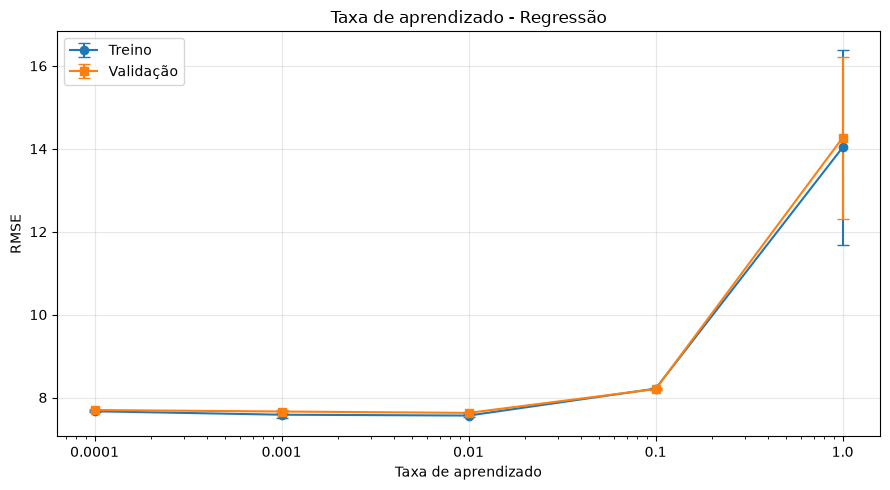

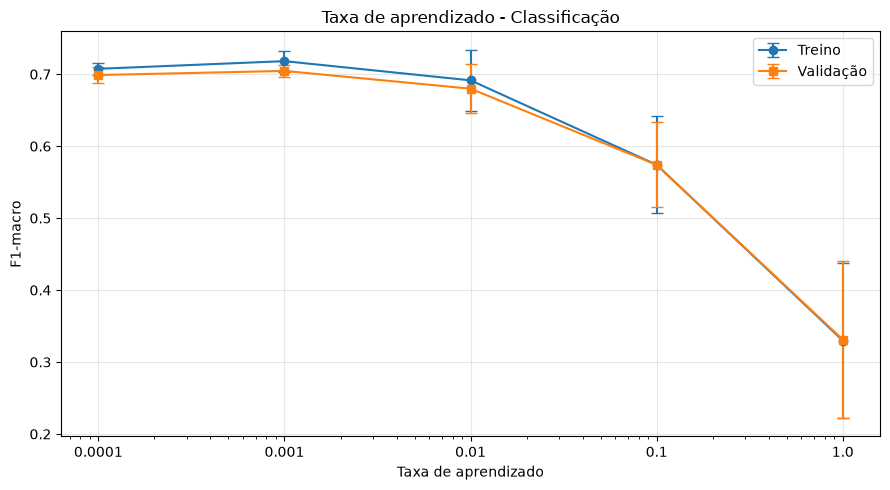

In [21]:
# Geração e salvamento dos gráficos de sensibilidade da taxa de aprendizado para regressão e classificação

plot_learning_rate(
    regression_lr_results,
    "regressão",
    "RMSE",
    "RMSE",
    "taxa_aprendizado_regressao.png"
)

plot_learning_rate(
    classification_lr_results,
    "classificação",
    "F1-macro",
    "F1-macro",
    "taxa_aprendizado_classificacao.png"
)

### Tamanho de Batch

In [16]:
# Definição dos valores testados para tamanho do lote de treinamento (batch size)

BATCH_SIZE_VALUES = [8, 32, 128, 512, 32000]

In [17]:
# Execução dos experimentos variando o tamanho de batch na regressão com múltiplas sementes

regression_batch_results = run_hyperparameter_experiment(
    datasets=regression_datasets,
    task="regression",
    base_config=BASELINE_CONFIG,
    parameter="batch_size",
    values=BATCH_SIZE_VALUES,
    seeds=SEEDS,
    target_scaler=target_scaler
)


Tarefa: regression
Hiperparâmetro: batch_size = 8
Arquitetura: (32, 32)

Executando regression | Seed: 42
Época [1/200] | Train Loss: 0.309297 | Val Loss: 0.274476
Época [2/200] | Train Loss: 0.269210 | Val Loss: 0.267476
Época [3/200] | Train Loss: 0.262528 | Val Loss: 0.255954
Época [4/200] | Train Loss: 0.257547 | Val Loss: 0.254613
Época [5/200] | Train Loss: 0.254367 | Val Loss: 0.251356
Época [6/200] | Train Loss: 0.253666 | Val Loss: 0.250494
Época [7/200] | Train Loss: 0.251808 | Val Loss: 0.246611
Época [8/200] | Train Loss: 0.250374 | Val Loss: 0.248667
Época [9/200] | Train Loss: 0.249290 | Val Loss: 0.251449
Época [10/200] | Train Loss: 0.248328 | Val Loss: 0.249734
Época [11/200] | Train Loss: 0.248113 | Val Loss: 0.250051
Época [12/200] | Train Loss: 0.247396 | Val Loss: 0.243877
Época [13/200] | Train Loss: 0.246243 | Val Loss: 0.248284
Época [14/200] | Train Loss: 0.246404 | Val Loss: 0.247704
Época [15/200] | Train Loss: 0.245873 | Val Loss: 0.247750
Época [16/200] | 

In [18]:
# Execução dos experimentos variando o tamanho de batch na classificação com múltiplas sementes

classification_batch_results = run_hyperparameter_experiment(
    datasets=classification_datasets,
    task="classification",
    base_config=BASELINE_CONFIG,
    parameter="batch_size",
    values=BATCH_SIZE_VALUES,
    seeds=SEEDS
)


Tarefa: classification
Hiperparâmetro: batch_size = 8
Arquitetura: (32, 32)

Executando classification | Seed: 42
Época [1/200] | Train Loss: 0.349086 | Val Loss: 0.318704
Época [2/200] | Train Loss: 0.313001 | Val Loss: 0.313636
Época [3/200] | Train Loss: 0.309576 | Val Loss: 0.310949
Época [4/200] | Train Loss: 0.306472 | Val Loss: 0.313211
Época [5/200] | Train Loss: 0.302534 | Val Loss: 0.313644
Época [6/200] | Train Loss: 0.300178 | Val Loss: 0.305298
Época [7/200] | Train Loss: 0.299189 | Val Loss: 0.302907
Época [8/200] | Train Loss: 0.296379 | Val Loss: 0.305793
Época [9/200] | Train Loss: 0.295012 | Val Loss: 0.298505
Época [10/200] | Train Loss: 0.294226 | Val Loss: 0.301535
Época [11/200] | Train Loss: 0.292387 | Val Loss: 0.299633
Época [12/200] | Train Loss: 0.290994 | Val Loss: 0.298916
Época [13/200] | Train Loss: 0.290101 | Val Loss: 0.308673
Época [14/200] | Train Loss: 0.289155 | Val Loss: 0.304983
Época [15/200] | Train Loss: 0.288894 | Val Loss: 0.312053
Época [16

In [19]:
# Exibição dos sumários estatísticos consolidados dos experimentos de tamanho de batch

regression_batch_summary = regression_batch_results[2]
classification_batch_summary = classification_batch_results[2]

display(regression_batch_summary)
display(classification_batch_summary)

train_metric           val_metric           generalization_gap  \
                     mean       std       mean       std               mean   
tested_value                                                                  
8                7.490991  0.040796   7.609456  0.014288           0.118465   
32               7.516010  0.102979   7.630936  0.040920           0.114926   
128              7.577459  0.098821   7.655624  0.050826           0.078165   
512              7.634894  0.025775   7.684740  0.009067           0.049846   
32000            8.272534  0.066731   8.291166  0.069205           0.018631   

                       best_epoch            epochs_trained             \
                   std       mean        std           mean        std   
tested_value                                                             
8             0.040708       41.0  14.265343           61.0  14.265343   
32            0.068746       56.2  32.560713           76.2  32.560713   
128           0.052621       80.0  50.044980          100.0  50.044980   
512           0.027272      108.0  27.230498          128.0  27.230498   
32000         0.009583      200.0   0.000000          200.0   0.000000   

             elapsed_time            trainable_params       
                     mean        std             mean  std  
tested_value                                                
8              131.481860  30.625777           1601.0  0.0  
32              48.601809  21.207465           1601.0  0.0  
128             39.480497  21.322205           1601.0  0.0  
512             36.137708   7.902502           1601.0  0.0  
32000           49.130968   0.322479           1601.0  0.0

train_metric           val_metric           generalization_gap  \
                     mean       std       mean       std               mean   
tested_value                                                                  
8                0.720934  0.014902   0.699226  0.010845           0.021709   
32               0.728043  0.016997   0.707354  0.006425           0.020689   
128              0.727963  0.016008   0.709144  0.005471           0.018819   
512              0.711962  0.012893   0.702899  0.008943           0.009063   
32000            0.529716  0.005056   0.533532  0.004391          -0.003817   

                       best_epoch            epochs_trained             \
                   std       mean        std           mean        std   
tested_value                                                             
8             0.017137       18.8   6.140033           38.8   6.140033   
32            0.018385       33.4  11.970798           53.4  11.970798   
128           0.015601       83.4  14.099645          103.4  14.099645   
512           0.006769      122.2  45.085474          142.0  44.760474   
32000         0.001025      200.0   0.000000          200.0   0.000000   

             elapsed_time             trainable_params       
                     mean         std             mean  std  
tested_value                                                 
8              236.890758  275.760379           1667.0  0.0  
32              50.086244    8.623685           1667.0  0.0  
128             43.061650    5.425520           1667.0  0.0  
512             43.992152   13.924134           1667.0  0.0  
32000           53.074001    0.226653           1667.0  0.0

In [20]:
# Ajuste do diretório de destino para exportação das figuras de tamanho de batch

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

REPORTS_DIR = PROJECT_ROOT / "reports"
TABLES_DIR = REPORTS_DIR / "tables"
FIGURES_DIR = REPORTS_DIR / "figures"

TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [21]:
# Definição da função de plotagem para os resultados de sensibilidade ao tamanho de batch

def plot_batch_size(results, task, ylabel, filename):
    summary = results[2]

    values = summary.index.astype(int)

    train_mean = summary[("train_metric", "mean")]
    train_std = summary[("train_metric", "std")]

    val_mean = summary[("val_metric", "mean")]
    val_std = summary[("val_metric", "std")]

    plt.figure(figsize=(9, 5))

    plt.errorbar(
        values,
        train_mean,
        yerr=train_std,
        marker="o",
        capsize=4,
        label="Treino"
    )

    plt.errorbar(
        values,
        val_mean,
        yerr=val_std,
        marker="s",
        capsize=4,
        label="Validação"
    )

    plt.xlabel("Tamanho do batch")
    plt.ylabel(ylabel)
    plt.title(f"Tamanho do batch - {task.capitalize()}")
    plt.xticks(values, [str(v) for v in values])
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        FIGURES_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

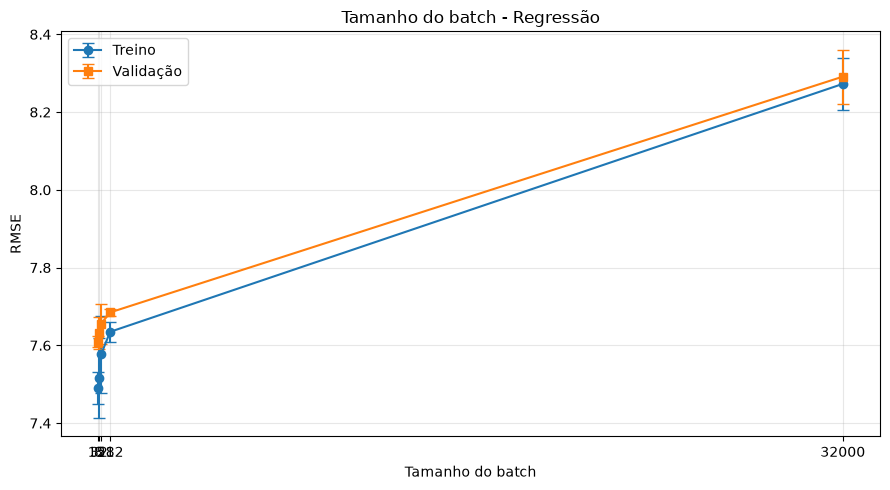

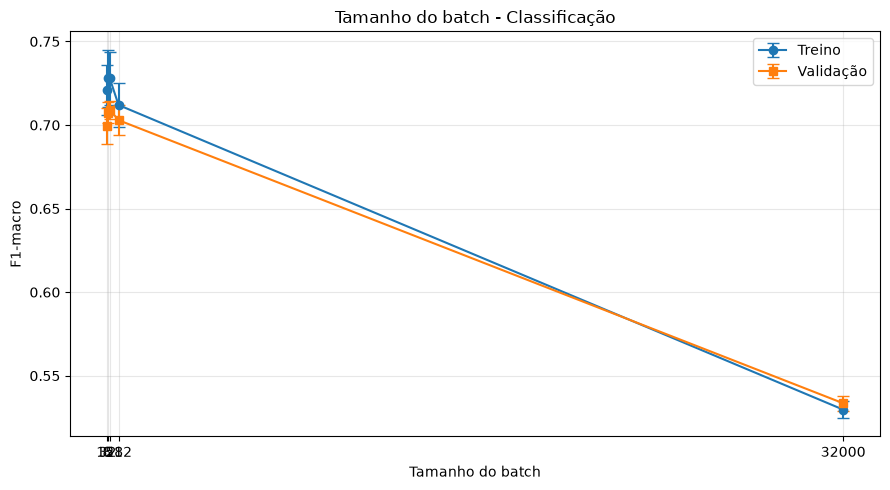

In [22]:
# Geração e salvamento dos gráficos comparativos de desempenho em função do tamanho de batch

plot_batch_size(
    regression_batch_results,
    "regressão",
    "RMSE",
    "batch_size_regressao.png"
)

plot_batch_size(
    classification_batch_results,
    "classificação",
    "F1-macro",
    "batch_size_classificacao.png"
)

In [8]:
# Definição dos valores testados para regularização L2 (weight decay)

WEIGHT_DECAY_VALUES = [
    0,
    1e-5,
    1e-4,
    1e-3,
    1e-2
]

In [9]:
# Execução dos experimentos variando o weight decay na regressão com múltiplas sementes

regression_weight_decay_results = run_hyperparameter_experiment(
    datasets=regression_datasets,
    task="regression",
    base_config=BASELINE_CONFIG,
    parameter="weight_decay",
    values=WEIGHT_DECAY_VALUES,
    seeds=SEEDS,
    target_scaler=target_scaler
)


Tarefa: regression
Hiperparâmetro: weight_decay = 0
Arquitetura: (32, 32)

Executando regression | Seed: 42
Época [1/200] | Train Loss: 0.385362 | Val Loss: 0.281131
Época [2/200] | Train Loss: 0.278449 | Val Loss: 0.270681
Época [3/200] | Train Loss: 0.270350 | Val Loss: 0.265886
Época [4/200] | Train Loss: 0.264908 | Val Loss: 0.264184
Época [5/200] | Train Loss: 0.261945 | Val Loss: 0.261782
Época [6/200] | Train Loss: 0.258798 | Val Loss: 0.257988
Época [7/200] | Train Loss: 0.256433 | Val Loss: 0.253566
Época [8/200] | Train Loss: 0.253920 | Val Loss: 0.255258
Época [9/200] | Train Loss: 0.252465 | Val Loss: 0.251204
Época [10/200] | Train Loss: 0.252423 | Val Loss: 0.252364
Época [11/200] | Train Loss: 0.250659 | Val Loss: 0.249543
Época [12/200] | Train Loss: 0.249211 | Val Loss: 0.250656
Época [13/200] | Train Loss: 0.249049 | Val Loss: 0.247506
Época [14/200] | Train Loss: 0.248212 | Val Loss: 0.247492
Época [15/200] | Train Loss: 0.247371 | Val Loss: 0.261515
Época [16/200] 

In [10]:
# Extração do sumário consolidado de resultados para weight decay na regressão

regression_weight_decay_summary = regression_weight_decay_results[2]

In [11]:
# Exibição do sumário estatístico de validação do weight decay na regressão

regression_weight_decay_summary

train_metric           val_metric           generalization_gap  \
                     mean       std       mean       std               mean   
tested_value                                                                  
0.00000          7.585635  0.081327   7.662731  0.041539           0.077096   
0.00001          7.556322  0.094957   7.639319  0.051105           0.082996   
0.00010          7.568926  0.092470   7.640294  0.050876           0.071368   
0.00100          7.676616  0.024792   7.675373  0.019071          -0.001243   
0.01000          7.897127  0.012309   7.879503  0.009360          -0.017624   

                       best_epoch            epochs_trained             \
                   std       mean        std           mean        std   
tested_value                                                             
0.00000       0.051146       58.0  30.033315           78.0  30.033315   
0.00001       0.049021       57.4  23.723406           77.4  23.723406   
0.00010       0.044434       73.2  35.067079           93.2  35.067079   
0.00100       0.018453       72.8  35.251950           92.8  35.251950   
0.01000       0.009141       53.6  17.472836           73.6  17.472836   

             elapsed_time            trainable_params       
                     mean        std             mean  std  
tested_value                                                
0.00000         53.995156  18.622317           1601.0  0.0  
0.00001         74.231094  33.140115           1601.0  0.0  
0.00010         78.377238  30.942560           1601.0  0.0  
0.00100         77.447205  32.862466           1601.0  0.0  
0.01000         66.414048  18.559421           1601.0  0.0

In [13]:
# Execução dos experimentos variando o weight decay na classificação com múltiplas sementes

classification_weight_decay_results = run_hyperparameter_experiment(
    datasets=classification_datasets,
    task="classification",
    base_config=BASELINE_CONFIG,
    parameter="weight_decay",
    values=WEIGHT_DECAY_VALUES,
    seeds=SEEDS
)


Tarefa: classification
Hiperparâmetro: weight_decay = 0
Arquitetura: (32, 32)

Executando classification | Seed: 42
Época [1/200] | Train Loss: 0.434234 | Val Loss: 0.336264
Época [2/200] | Train Loss: 0.320730 | Val Loss: 0.315244
Época [3/200] | Train Loss: 0.309885 | Val Loss: 0.314060
Época [4/200] | Train Loss: 0.306436 | Val Loss: 0.311653
Época [5/200] | Train Loss: 0.305447 | Val Loss: 0.310753
Época [6/200] | Train Loss: 0.304675 | Val Loss: 0.327201
Época [7/200] | Train Loss: 0.302588 | Val Loss: 0.310376
Época [8/200] | Train Loss: 0.301745 | Val Loss: 0.309787
Época [9/200] | Train Loss: 0.301068 | Val Loss: 0.307493
Época [10/200] | Train Loss: 0.300107 | Val Loss: 0.315940
Época [11/200] | Train Loss: 0.299458 | Val Loss: 0.314308
Época [12/200] | Train Loss: 0.299217 | Val Loss: 0.309533
Época [13/200] | Train Loss: 0.299329 | Val Loss: 0.307495
Época [14/200] | Train Loss: 0.298442 | Val Loss: 0.308050
Época [15/200] | Train Loss: 0.296944 | Val Loss: 0.307870
Época [

In [14]:
# Extração e exibição do sumário estatístico de validação do weight decay na classificação

classification_weight_decay_summary = classification_weight_decay_results[2]
classification_weight_decay_summary

train_metric           val_metric           generalization_gap  \
                     mean       std       mean       std               mean   
tested_value                                                                  
0.00000          0.718141  0.014502   0.704567  0.008410           0.013574   
0.00001          0.721486  0.009431   0.705101  0.006347           0.016384   
0.00010          0.719208  0.012398   0.703330  0.005740           0.015877   
0.00100          0.685803  0.010948   0.683989  0.008065           0.001814   
0.01000          0.542492  0.000870   0.546682  0.001053          -0.004190   

                       best_epoch            epochs_trained             \
                   std       mean        std           mean        std   
tested_value                                                             
0.00000       0.007236       54.2  10.009995           74.2  10.009995   
0.00001       0.005291       49.8   4.147288           69.8   4.147288   
0.00010       0.007718       65.4   9.502631           85.4   9.502631   
0.00100       0.005228       72.6  12.198361           92.6  12.198361   
0.01000       0.000565       31.0   9.300538           51.0   9.300538   

             elapsed_time            trainable_params       
                     mean        std             mean  std  
tested_value                                                
0.00000         48.497977   8.531823           1667.0  0.0  
0.00001         45.246825   3.944853           1667.0  0.0  
0.00010         58.564177   6.508558           1667.0  0.0  
0.00100         89.610932  39.474937           1667.0  0.0  
0.01000         35.168260   7.947856           1667.0  0.0

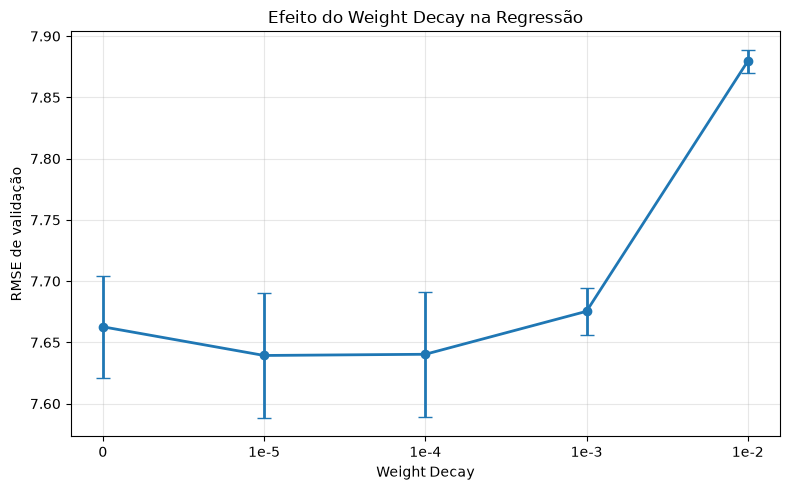

In [21]:
# Geração e salvamento do gráfico de impacto do weight decay na regressão
weight_decay_values = ["0", "1e-5", "1e-4", "1e-3", "1e-2"]

# RMSE de validação: média e desvio-padrão
rmse_mean = [7.662731, 7.639319, 7.640294, 7.675373, 7.879503]
rmse_std = [0.041539, 0.051105, 0.050876, 0.019071, 0.009360]

plt.figure(figsize=(8, 5))

plt.errorbar(
    weight_decay_values,
    rmse_mean,
    yerr=rmse_std,
    marker="o",
    capsize=5,
    linewidth=2
)

plt.xlabel("Weight Decay")
plt.ylabel("RMSE de validação")
plt.title("Efeito do Weight Decay na Regressão")
plt.grid(True, alpha=0.3)
plt.tight_layout()

Path("../reports/figures").mkdir(parents=True, exist_ok=True)
plt.savefig(
    "../reports/figures/weight_decay_regressao.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


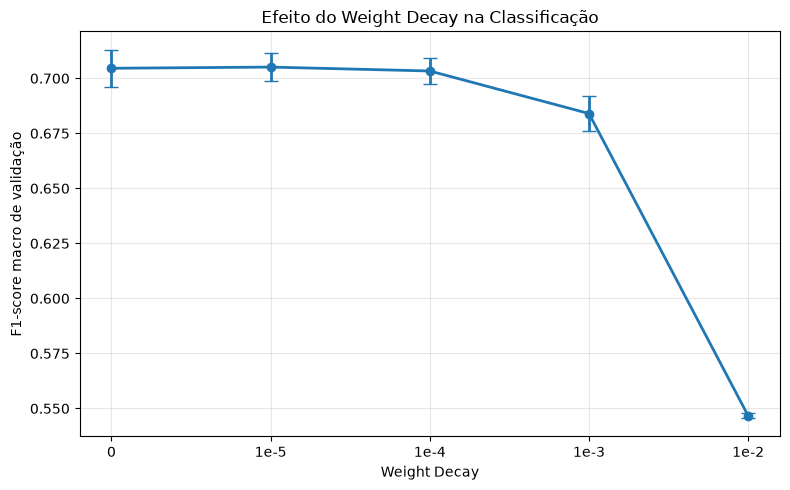

In [20]:
# Geração e salvamento do gráfico de impacto do weight decay na classificação
weight_decay_values = ["0", "1e-5", "1e-4", "1e-3", "1e-2"]

# F1-score macro de validação: média e desvio-padrão
f1_mean = [0.704567, 0.705101, 0.703330, 0.683989, 0.546682]
f1_std = [0.008410, 0.006347, 0.005740, 0.008065, 0.001053]

plt.figure(figsize=(8, 5))

plt.errorbar(
    weight_decay_values,
    f1_mean,
    yerr=f1_std,
    marker="o",
    capsize=5,
    linewidth=2
)

plt.xlabel("Weight Decay")
plt.ylabel("F1-score macro de validação")
plt.title("Efeito do Weight Decay na Classificação")
plt.grid(True, alpha=0.3)
plt.tight_layout()

Path("../reports/figures").mkdir(parents=True, exist_ok=True)

plt.savefig(
    "../reports/figures/weight_decay_classificacao.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### Funções de Perda

In [7]:
# Definição das funções de perda avaliadas para a tarefa de regressão (MSE, MAE, Huber)
loss_values_regression = [
    "mse",
    "mae",
    "huber",
]

In [8]:
# Execução dos experimentos comparando as funções de perda na regressão com múltiplas sementes

results_loss_reg, detailed_loss_reg, summary_loss_reg = run_hyperparameter_experiment(
    datasets=regression_datasets,
    task="regression",
    base_config=BASELINE_CONFIG.copy(),
    parameter="loss",
    values=loss_values_regression,
    seeds=SEEDS,
    target_scaler=target_scaler,
)


Tarefa: regression
Hiperparâmetro: loss = mse
Arquitetura: (32, 32)

Executando regression | Seed: 42
Época [1/200] | Train Loss: 0.385362 | Val Loss: 0.281131
Época [2/200] | Train Loss: 0.278449 | Val Loss: 0.270681
Época [3/200] | Train Loss: 0.270350 | Val Loss: 0.265886
Época [4/200] | Train Loss: 0.264908 | Val Loss: 0.264184
Época [5/200] | Train Loss: 0.261945 | Val Loss: 0.261782
Época [6/200] | Train Loss: 0.258798 | Val Loss: 0.257988
Época [7/200] | Train Loss: 0.256433 | Val Loss: 0.253566
Época [8/200] | Train Loss: 0.253920 | Val Loss: 0.255258
Época [9/200] | Train Loss: 0.252465 | Val Loss: 0.251204
Época [10/200] | Train Loss: 0.252423 | Val Loss: 0.252364
Época [11/200] | Train Loss: 0.250659 | Val Loss: 0.249543
Época [12/200] | Train Loss: 0.249211 | Val Loss: 0.250656
Época [13/200] | Train Loss: 0.249049 | Val Loss: 0.247506
Época [14/200] | Train Loss: 0.248212 | Val Loss: 0.247492
Época [15/200] | Train Loss: 0.247371 | Val Loss: 0.261515
Época [16/200] | Trai

In [10]:
# Exibição do sumário estatístico comparativo das funções de perda na regressão

summary_loss_reg

train_metric           val_metric           generalization_gap  \
                     mean       std       mean       std               mean   
tested_value                                                                  
huber            7.552195  0.111378   7.651923  0.048911           0.099728   
mae              7.592202  0.071582   7.697678  0.043340           0.105476   
mse              7.585635  0.081327   7.662731  0.041539           0.077096   

                       best_epoch            epochs_trained             \
                   std       mean        std           mean        std   
tested_value                                                             
huber         0.064168       66.2  30.922484           86.2  30.922484   
mae           0.037508       75.2  21.741665           95.2  21.741665   
mse           0.051146       58.0  30.033315           78.0  30.033315   

             elapsed_time             trainable_params       
                     mean         std             mean  std  
tested_value                                                 
huber           35.830753   12.913126           1601.0  0.0  
mae             88.443311  111.151096           1601.0  0.0  
mse             31.101231   11.618960           1601.0  0.0

In [9]:
# Definição das funções de perda avaliadas para classificação (CrossEntropy padrão vs ponderada)

loss_values_classification = [
    "cross_entropy",
    "cross_entropy_weighted",
]

results_loss_cls, detailed_loss_cls, summary_loss_cls = run_hyperparameter_experiment(
    datasets=classification_datasets,
    task="classification",
    base_config=BASELINE_CONFIG.copy(),
    parameter="loss",
    values=loss_values_classification,
    seeds=SEEDS,
)


Tarefa: classification
Hiperparâmetro: loss = cross_entropy
Arquitetura: (32, 32)

Executando classification | Seed: 42
Época [1/200] | Train Loss: 0.434234 | Val Loss: 0.336264
Época [2/200] | Train Loss: 0.320730 | Val Loss: 0.315244
Época [3/200] | Train Loss: 0.309885 | Val Loss: 0.314060
Época [4/200] | Train Loss: 0.306436 | Val Loss: 0.311653
Época [5/200] | Train Loss: 0.305447 | Val Loss: 0.310753
Época [6/200] | Train Loss: 0.304675 | Val Loss: 0.327201
Época [7/200] | Train Loss: 0.302588 | Val Loss: 0.310376
Época [8/200] | Train Loss: 0.301745 | Val Loss: 0.309787
Época [9/200] | Train Loss: 0.301068 | Val Loss: 0.307493
Época [10/200] | Train Loss: 0.300107 | Val Loss: 0.315940
Época [11/200] | Train Loss: 0.299458 | Val Loss: 0.314308
Época [12/200] | Train Loss: 0.299217 | Val Loss: 0.309533
Época [13/200] | Train Loss: 0.299329 | Val Loss: 0.307495
Época [14/200] | Train Loss: 0.298442 | Val Loss: 0.308050
Época [15/200] | Train Loss: 0.296944 | Val Loss: 0.307870
Épo

In [11]:
# Exibição do sumário comparativo entre CrossEntropy padrão e ponderada na classificação

summary_loss_cls

train_metric           val_metric            \
                               mean       std       mean       std   
tested_value                                                         
cross_entropy              0.718141  0.014502   0.704567  0.008410   
cross_entropy_weighted     0.647360  0.014095   0.629620  0.012624   

                       generalization_gap           best_epoch             \
                                     mean       std       mean        std   
tested_value                                                                
cross_entropy                    0.013574  0.007236       54.2  10.009995   
cross_entropy_weighted           0.017740  0.003650       24.8   6.534524   

                       epochs_trained            elapsed_time              \
                                 mean        std         mean         std   
tested_value                                                                
cross_entropy                    74.2  10.009995    44.398184    8.225687   
cross_entropy_weighted           44.8   6.534524    79.787961  115.015929   

                       trainable_params       
                                   mean  std  
tested_value                                  
cross_entropy                    1667.0  0.0  
cross_entropy_weighted           1667.0  0.0

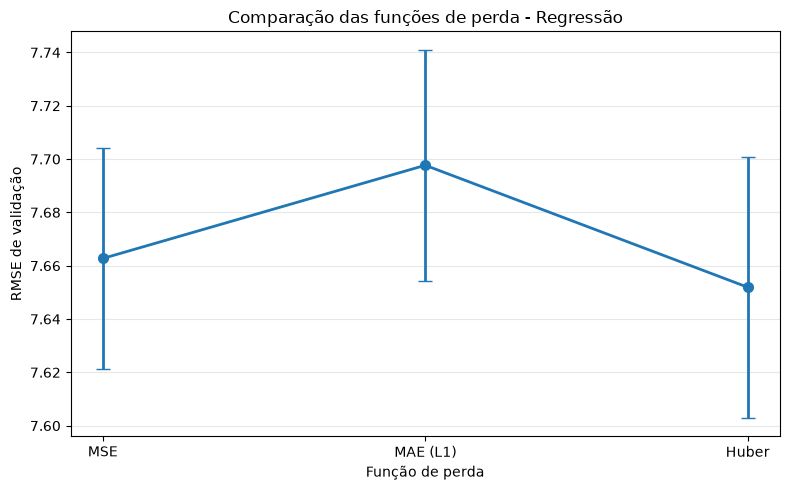

In [12]:
# Geração e salvamento do gráfico comparativo de funções de perda na regressão
loss_order_reg = ["mse", "mae", "huber"]

# Calcula média e desvio-padrão da métrica de validação
plot_reg = (
    detailed_loss_reg
    .groupby("tested_value")["val_metric"]
    .agg(["mean", "std"])
    .reindex(loss_order_reg)
)

labels_reg = ["MSE", "MAE (L1)", "Huber"]

plt.figure(figsize=(8, 5))

plt.errorbar(
    labels_reg,
    plot_reg["mean"],
    yerr=plot_reg["std"],
    fmt="o-",
    capsize=5,
    linewidth=2,
    markersize=7
)

plt.xlabel("Função de perda")
plt.ylabel("RMSE de validação")
plt.title("Comparação das funções de perda - Regressão")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../reports/figures/loss_regressao.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


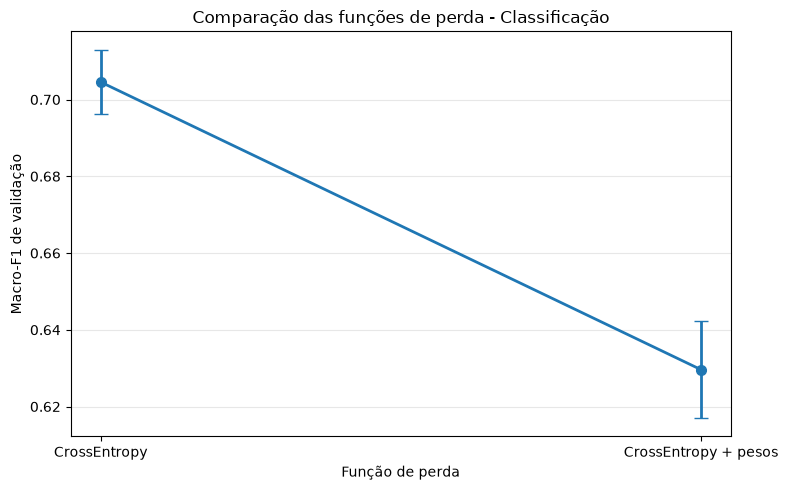

In [13]:
# Geração e salvamento do gráfico comparativo de funções de perda na classificação

loss_order_cls = [
    "cross_entropy",
    "cross_entropy_weighted"
]

plot_cls = (
    detailed_loss_cls
    .groupby("tested_value")["val_metric"]
    .agg(["mean", "std"])
    .reindex(loss_order_cls)
)

labels_cls = [
    "CrossEntropy",
    "CrossEntropy + pesos"
]

plt.figure(figsize=(8, 5))

plt.errorbar(
    labels_cls,
    plot_cls["mean"],
    yerr=plot_cls["std"],
    fmt="o-",
    capsize=5,
    linewidth=2,
    markersize=7
)

plt.xlabel("Função de perda")
plt.ylabel("Macro-F1 de validação")
plt.title("Comparação das funções de perda - Classificação")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../reports/figures/loss_classificacao.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [6]:
# Definição da grade bidimensional de interação: quantidade de neurônios vs regularização L2 (weight decay)

neurons_values = [8, 16, 32, 64]

weight_decay_values = [
    0,
    1e-5,
    1e-4,
    1e-3,
]

In [7]:
# Execução do experimento de interação bidimensional na tarefa de regressão

results_interaction_reg, detailed_interaction_reg, summary_interaction_reg = (
    run_interaction_experiment(
        datasets=regression_datasets,
        task="regression",
        base_config=BASELINE_CONFIG,
        neurons_values=neurons_values,
        weight_decay_values=weight_decay_values,
        seeds=SEEDS,
        target_scaler=target_scaler,
    )
)


Tarefa: regression
Neurônios: 8
Weight decay: 0
Arquitetura: (8, 8)

Executando regression | Seed: 42
Época [1/200] | Train Loss: 0.535763 | Val Loss: 0.351189
Época [2/200] | Train Loss: 0.318801 | Val Loss: 0.297077
Época [3/200] | Train Loss: 0.287231 | Val Loss: 0.275860
Época [4/200] | Train Loss: 0.274257 | Val Loss: 0.271673
Época [5/200] | Train Loss: 0.270942 | Val Loss: 0.268458
Época [6/200] | Train Loss: 0.269641 | Val Loss: 0.268122
Época [7/200] | Train Loss: 0.268864 | Val Loss: 0.268449
Época [8/200] | Train Loss: 0.268038 | Val Loss: 0.266385
Época [9/200] | Train Loss: 0.267713 | Val Loss: 0.265297
Época [10/200] | Train Loss: 0.267324 | Val Loss: 0.265814
Época [11/200] | Train Loss: 0.266347 | Val Loss: 0.265075
Época [12/200] | Train Loss: 0.264975 | Val Loss: 0.265600
Época [13/200] | Train Loss: 0.264106 | Val Loss: 0.262826
Época [14/200] | Train Loss: 0.263246 | Val Loss: 0.261856
Época [15/200] | Train Loss: 0.262334 | Val Loss: 0.264270
Época [16/200] | Trai

In [8]:
# Definição da função para geração e formatação do mapa de calor (heatmap) de interação

import matplotlib.pyplot as plt
import numpy as np

def plot_interaction_heatmap(
    detailed_df,
    task,
    metric,
    title,
    filename,
):
    # Calcular a média da métrica para cada combinação
    heatmap_data = detailed_df.pivot_table(
        index="neurons",
        columns="weight_decay",
        values=metric,
        aggfunc="mean",
    )

    fig, ax = plt.subplots(figsize=(9, 6))

    values = heatmap_data.values

    # Para regressão, valores menores são melhores.
    # Para classificação, valores maiores são melhores.
    cmap = "viridis"

    im = ax.imshow(
        values,
        aspect="auto",
        cmap=cmap,
    )

    # Rótulos dos eixos
    ax.set_xticks(range(len(heatmap_data.columns)))
    ax.set_xticklabels([
        f"{v:.0e}" if v != 0 else "0"
        for v in heatmap_data.columns
    ])

    ax.set_yticks(range(len(heatmap_data.index)))
    ax.set_yticklabels(heatmap_data.index)

    ax.set_xlabel("Weight decay")
    ax.set_ylabel("Neurônios por camada")
    ax.set_title(title)

    # Mostrar os valores nas células
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(
                j,
                i,
                f"{values[i, j]:.4f}",
                ha="center",
                va="center",
                color="white",
            )

    fig.colorbar(im, ax=ax, label=metric)

    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

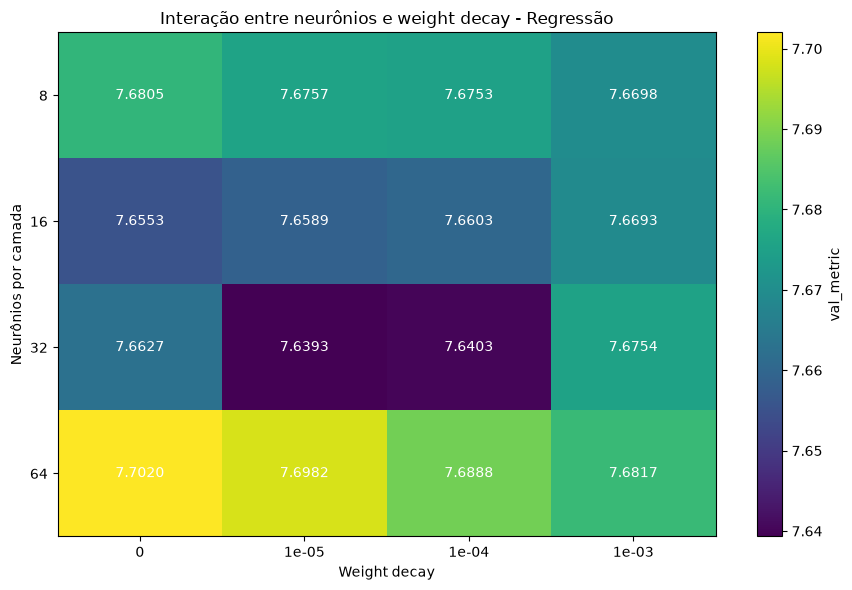

In [9]:
# Geração e salvamento do heatmap de interação (neurônios vs weight decay) para regressão

plot_interaction_heatmap(
    detailed_df=detailed_interaction_reg,
    task="regression",
    metric="val_metric",
    title="Interação entre neurônios e weight decay - Regressão",
    filename="../reports/figures/interacao_regressao.png",
)

In [11]:
# Execução do experimento de interação bidimensional na tarefa de classificação

results_interaction_cls, detailed_interaction_cls, summary_interaction_cls = (
    run_interaction_experiment(
        datasets=classification_datasets,
        task="classification",
        base_config=BASELINE_CONFIG,
        neurons_values=neurons_values,
        weight_decay_values=weight_decay_values,
        seeds=SEEDS,
    )
)


Tarefa: classification
Neurônios: 8
Weight decay: 0
Arquitetura: (8, 8)

Executando classification | Seed: 42
Época [1/200] | Train Loss: 0.505421 | Val Loss: 0.373856
Época [2/200] | Train Loss: 0.358458 | Val Loss: 0.341652
Época [3/200] | Train Loss: 0.331694 | Val Loss: 0.328696
Época [4/200] | Train Loss: 0.321101 | Val Loss: 0.323605
Época [5/200] | Train Loss: 0.316387 | Val Loss: 0.317819
Época [6/200] | Train Loss: 0.312893 | Val Loss: 0.318802
Época [7/200] | Train Loss: 0.310229 | Val Loss: 0.314853
Época [8/200] | Train Loss: 0.308870 | Val Loss: 0.317650
Época [9/200] | Train Loss: 0.307727 | Val Loss: 0.312084
Época [10/200] | Train Loss: 0.306927 | Val Loss: 0.316571
Época [11/200] | Train Loss: 0.306203 | Val Loss: 0.311176
Época [12/200] | Train Loss: 0.305511 | Val Loss: 0.310474
Época [13/200] | Train Loss: 0.305689 | Val Loss: 0.309765
Época [14/200] | Train Loss: 0.304744 | Val Loss: 0.314463
Época [15/200] | Train Loss: 0.304402 | Val Loss: 0.311240
Época [16/200

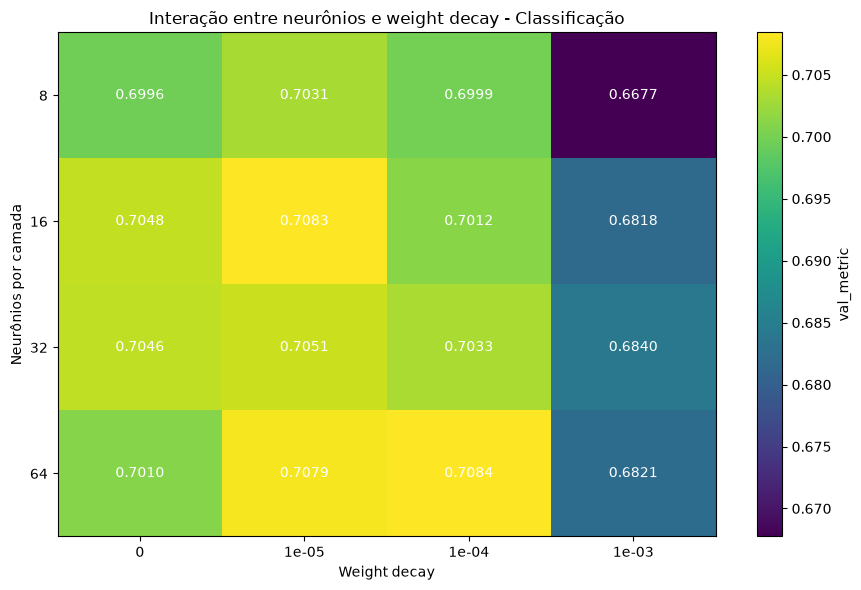

In [12]:
# Geração e salvamento do heatmap de interação (neurônios vs weight decay) para classificação

plot_interaction_heatmap(
    detailed_df=detailed_interaction_cls,
    task="classification",
    metric="val_metric",
    title="Interação entre neurônios e weight decay - Classificação",
    filename="../reports/figures/interacao_classificacao.png",
)

In [10]:
# Definição da grade reduzida de busca final combinando os melhores hiperparâmetros identificados

regression_grid = [
    {
        "hidden": (16, 16),
        "activation": "Tanh",
        "optimizer": "rmsprop",
        "lr": 0.01,
        "batch_size": 8,
        "weight_decay": 1e-5,
        "loss": "huber",
    },
    {
        "hidden": (32, 32),
        "activation": "Tanh",
        "optimizer": "rmsprop",
        "lr": 0.01,
        "batch_size": 8,
        "weight_decay": 1e-5,
        "loss": "huber",
    },
    {
        "hidden": (16, 16, 16, 16, 16),
        "activation": "Tanh",
        "optimizer": "rmsprop",
        "lr": 0.01,
        "batch_size": 8,
        "weight_decay": 1e-5,
        "loss": "huber",
    },
    {
        "hidden": (32, 32, 32, 32, 32),
        "activation": "Tanh",
        "optimizer": "adam",
        "lr": 0.01,
        "batch_size": 8,
        "weight_decay": 1e-5,
        "loss": "huber",
    },
    {
        "hidden": (32, 32),
        "activation": "ReLU",
        "optimizer": "adam",
        "lr": 0.001,
        "batch_size": 32,
        "weight_decay": 0,
        "loss": "mse",
    },
    {
        "hidden": (32, 32, 32, 32, 32),
        "activation": "Tanh",
        "optimizer": "rmsprop",
        "lr": 0.001,
        "batch_size": 32,
        "weight_decay": 1e-4,
        "loss": "mse",
    },
]


classification_grid = [
    {
        "hidden": (16, 16),
        "activation": "Tanh",
        "optimizer": "rmsprop",
        "lr": 0.001,
        "batch_size": 128,
        "weight_decay": 1e-5,
    },
    {
        "hidden": (64, 64),
        "activation": "Tanh",
        "optimizer": "rmsprop",
        "lr": 0.001,
        "batch_size": 128,
        "weight_decay": 1e-4,
    },
    {
        "hidden": (32, 32, 32, 32, 32),
        "activation": "Tanh",
        "optimizer": "rmsprop",
        "lr": 0.001,
        "batch_size": 128,
        "weight_decay": 1e-5,
    },
    {
        "hidden": (16,),
        "activation": "Tanh",
        "optimizer": "sgd_momentum",
        "lr": 0.001,
        "batch_size": 32,
        "weight_decay": 1e-5,
    },
    {
        "hidden": (32, 32),
        "activation": "LeakyReLU",
        "optimizer": "rmsprop",
        "lr": 0.0001,
        "batch_size": 32,
        "weight_decay": 1e-5,
    },
    {
        "hidden": (64, 64, 64, 64, 64),
        "activation": "Tanh",
        "optimizer": "sgd_momentum",
        "lr": 0.001,
        "batch_size": 128,
        "weight_decay": 1e-4,
    },
]

In [11]:
# Definição do subconjunto de sementes aleatórias para execução da busca em grade final
search_seeds = SEEDS[:3]


def execute_grid(datasets, task, baseline_config, grid, seeds,
                 target_scaler=None):

    results = []

    for i, grid_config in enumerate(grid, start=1):
        config = baseline_config.copy()
        config.update(grid_config)

        print(f"\n[{task}] Configuração {i}/{len(grid)}")

        run_results, results_df, summary = run_multiple_seeds(
            datasets=datasets,
            task=task,
            config=config,
            seeds=seeds,
            target_scaler=target_scaler
        )

        results.append({
            "configuration": i,
            "config": config,
            "results": run_results,
            "results_df": results_df,
            "summary": summary
        })

    return results

In [12]:
# Execução da busca em grade final sobre o conjunto de validação para regressão

regression_results = execute_grid(
    datasets=regression_datasets,
    task="regression",
    baseline_config=BASELINE_CONFIG,
    grid=regression_grid,
    seeds=search_seeds,
    target_scaler=target_scaler
)


[regression] Configuração 1/6

Executando regression | Seed: 42
Época [1/200] | Train Loss: 0.153477 | Val Loss: 0.142430
Época [2/200] | Train Loss: 0.139932 | Val Loss: 0.137547
Época [3/200] | Train Loss: 0.135882 | Val Loss: 0.136565
Época [4/200] | Train Loss: 0.134589 | Val Loss: 0.127837
Época [5/200] | Train Loss: 0.133771 | Val Loss: 0.142798
Época [6/200] | Train Loss: 0.133873 | Val Loss: 0.136120
Época [7/200] | Train Loss: 0.133377 | Val Loss: 0.128703
Época [8/200] | Train Loss: 0.132448 | Val Loss: 0.131269
Época [9/200] | Train Loss: 0.132099 | Val Loss: 0.135478
Época [10/200] | Train Loss: 0.131411 | Val Loss: 0.129260
Época [11/200] | Train Loss: 0.131171 | Val Loss: 0.126990
Época [12/200] | Train Loss: 0.131160 | Val Loss: 0.123267
Época [13/200] | Train Loss: 0.130539 | Val Loss: 0.131444
Época [14/200] | Train Loss: 0.130366 | Val Loss: 0.125016
Época [15/200] | Train Loss: 0.130141 | Val Loss: 0.129779
Época [16/200] | Train Loss: 0.130055 | Val Loss: 0.131845


In [13]:
# Execução da busca em grade final sobre o conjunto de validação para classificação

classification_results = execute_grid(
    datasets=classification_datasets,
    task="classification",
    baseline_config=BASELINE_CONFIG,
    grid=classification_grid,
    seeds=search_seeds
)


[classification] Configuração 1/6

Executando classification | Seed: 42
Época [1/200] | Train Loss: 0.430415 | Val Loss: 0.367142
Época [2/200] | Train Loss: 0.357488 | Val Loss: 0.349763
Época [3/200] | Train Loss: 0.340450 | Val Loss: 0.335440
Época [4/200] | Train Loss: 0.327165 | Val Loss: 0.326403
Época [5/200] | Train Loss: 0.319996 | Val Loss: 0.323445
Época [6/200] | Train Loss: 0.315799 | Val Loss: 0.320983
Época [7/200] | Train Loss: 0.312710 | Val Loss: 0.315791
Época [8/200] | Train Loss: 0.309883 | Val Loss: 0.313873
Época [9/200] | Train Loss: 0.307442 | Val Loss: 0.310840
Época [10/200] | Train Loss: 0.305653 | Val Loss: 0.310723
Época [11/200] | Train Loss: 0.303582 | Val Loss: 0.308204
Época [12/200] | Train Loss: 0.302057 | Val Loss: 0.307802
Época [13/200] | Train Loss: 0.300836 | Val Loss: 0.307657
Época [14/200] | Train Loss: 0.299851 | Val Loss: 0.306014
Época [15/200] | Train Loss: 0.298989 | Val Loss: 0.305709
Época [16/200] | Train Loss: 0.297845 | Val Loss: 0

In [14]:
# Definição da função auxiliar para consolidação, ordenação e ranking das configurações da grade

def summarize_grid_results(grid_results, task):

    rows = []

    for item in grid_results:
        summary = item["summary"]

        rows.append({
            "configuracao": item["configuration"],
            "val_mean": summary.loc["val_metric", "mean"],
            "val_std": summary.loc["val_metric", "std"],
            "gap_mean": summary.loc["generalization_gap", "mean"],
            "tempo_medio": summary.loc["elapsed_time", "mean"],
            "config": item["config"]
        })

    df = pd.DataFrame(rows)

    # Regressão: menor RMSE é melhor.
    # Classificação: maior F1-macro é melhor.
    df = df.sort_values(
        "val_mean",
        ascending=(task == "regression")
    ).reset_index(drop=True)

    return df

In [15]:
# Sumarização e cálculo do ranking das configurações candidatas para regressão

regression_ranking = summarize_grid_results(
    regression_results,
    task="regression"
)

classification_ranking = summarize_grid_results(
    classification_results,
    task="classification"
)

In [22]:
# Exibição dos rankings comparativos das melhores configurações encontradas na validação

display(regression_ranking)
display(classification_ranking)

,configuracao,val_mean,val_std,gap_mean,tempo_medio,config
0,5,7.631231,0.056522,0.140088,61.758360,"{'hidden': (32, 32), 'activation': 'ReLU', 'op..."
1,6,7.634035,0.007478,0.055922,68.414227,"{'hidden': (32, 32, 32, 32, 32), 'activation':..."
2,1,7.776979,0.047734,0.033008,125.525107,"{'hidden': (16, 16), 'activation': 'Tanh', 'op..."
3,2,7.993308,0.032525,0.049282,96.649141,"{'hidden': (32, 32), 'activation': 'Tanh', 'op..."
4,3,8.504594,0.120314,-0.061740,127.847112,"{'hidden': (16, 16, 16, 16, 16), 'activation':..."
5,4,8.546122,0.078195,-0.036591,369.021502,"{'hidden': (32, 32, 32, 32, 32), 'activation':..."


,configuracao,val_mean,val_std,gap_mean,tempo_medio,config
0,1,0.721042,0.011648,0.003141,72.763511,"{'hidden': (16, 16), 'activation': 'Tanh', 'op..."
1,3,0.710038,0.001009,0.020230,45.994082,"{'hidden': (32, 32, 32, 32, 32), 'activation':..."
2,2,0.708865,0.009144,0.017145,36.835134,"{'hidden': (64, 64), 'activation': 'Tanh', 'op..."
3,4,0.707820,0.001305,-0.003467,133.203667,"{'hidden': (16,), 'activation': 'Tanh', 'optim..."
4,5,0.704377,0.018726,0.009702,180.233457,"{'hidden': (32, 32), 'activation': 'LeakyReLU'..."
5,6,0.695697,0.002748,0.021167,101.833619,"{'hidden': (64, 64, 64, 64, 64), 'activation':..."


In [16]:
# Seleção da melhor configuração hiperparamétrica para regressão e classificação

best_regression = regression_ranking.iloc[0]
best_classification = classification_ranking.iloc[0]

print("MELHOR CONFIGURAÇÃO - REGRESSÃO")
print(best_regression)

print("\nMELHOR CONFIGURAÇÃO - CLASSIFICAÇÃO")
print(best_classification)

MELHOR CONFIGURAÇÃO - REGRESSÃO
configuracao                                                    5
val_mean                                                 7.631231
val_std                                                  0.056522
gap_mean                                                 0.140088
tempo_medio                                             57.420652
config          {'hidden': (32, 32), 'activation': 'ReLU', 'op...
Name: 0, dtype: object

MELHOR CONFIGURAÇÃO - CLASSIFICAÇÃO
configuracao                                                    1
val_mean                                                 0.721042
val_std                                                  0.011648
gap_mean                                                 0.003141
tempo_medio                                             99.349783
config          {'hidden': (16, 16), 'activation': 'Tanh', 'op...
Name: 0, dtype: object


In [17]:
# Treinamento completo multissemente da configuração final vencedora para regressão
final_regression_config = best_regression["config"]

final_regression_results, final_regression_df, final_regression_summary = (
    run_multiple_seeds(
        datasets=regression_datasets,
        task="regression",
        config=final_regression_config,
        seeds=SEEDS,
        target_scaler=target_scaler
    )
)


Executando regression | Seed: 42
Época [1/200] | Train Loss: 0.343677 | Val Loss: 0.278493
Época [2/200] | Train Loss: 0.275449 | Val Loss: 0.283675
Época [3/200] | Train Loss: 0.268010 | Val Loss: 0.266596
Época [4/200] | Train Loss: 0.262447 | Val Loss: 0.263377
Época [5/200] | Train Loss: 0.258438 | Val Loss: 0.259951
Época [6/200] | Train Loss: 0.256470 | Val Loss: 0.255455
Época [7/200] | Train Loss: 0.254170 | Val Loss: 0.252027
Época [8/200] | Train Loss: 0.252581 | Val Loss: 0.254681
Época [9/200] | Train Loss: 0.250111 | Val Loss: 0.249813
Época [10/200] | Train Loss: 0.249265 | Val Loss: 0.249040
Época [11/200] | Train Loss: 0.248050 | Val Loss: 0.248023
Época [12/200] | Train Loss: 0.247219 | Val Loss: 0.245960
Época [13/200] | Train Loss: 0.246222 | Val Loss: 0.253666
Época [14/200] | Train Loss: 0.245718 | Val Loss: 0.244496
Época [15/200] | Train Loss: 0.245350 | Val Loss: 0.259459
Época [16/200] | Train Loss: 0.245041 | Val Loss: 0.248053
Época [17/200] | Train Loss: 0.

KeyboardInterrupt: 

In [20]:
# Treinamento completo multissemente da configuração final vencedora para classificação
final_classification_config = best_classification["config"]

final_classification_results, final_classification_df, final_classification_summary = (
    run_multiple_seeds(
        datasets=classification_datasets,
        task="classification",
        config=final_classification_config,
        seeds=SEEDS
    )
)


Executando classification | Seed: 42
Época [1/200] | Train Loss: 0.430415 | Val Loss: 0.367142
Época [2/200] | Train Loss: 0.357488 | Val Loss: 0.349763
Época [3/200] | Train Loss: 0.340450 | Val Loss: 0.335440
Época [4/200] | Train Loss: 0.327165 | Val Loss: 0.326403
Época [5/200] | Train Loss: 0.319996 | Val Loss: 0.323445
Época [6/200] | Train Loss: 0.315799 | Val Loss: 0.320983
Época [7/200] | Train Loss: 0.312710 | Val Loss: 0.315791
Época [8/200] | Train Loss: 0.309883 | Val Loss: 0.313873
Época [9/200] | Train Loss: 0.307442 | Val Loss: 0.310840
Época [10/200] | Train Loss: 0.305653 | Val Loss: 0.310723
Época [11/200] | Train Loss: 0.303582 | Val Loss: 0.308204
Época [12/200] | Train Loss: 0.302057 | Val Loss: 0.307802
Época [13/200] | Train Loss: 0.300836 | Val Loss: 0.307657
Época [14/200] | Train Loss: 0.299851 | Val Loss: 0.306014
Época [15/200] | Train Loss: 0.298989 | Val Loss: 0.305709
Época [16/200] | Train Loss: 0.297845 | Val Loss: 0.303970
Época [17/200] | Train Loss

KeyboardInterrupt: 

In [26]:
# Exibição dos sumários estatísticos finais de validação dos modelos vencedores

display(final_regression_summary)
display(final_classification_summary)

,mean,std
train_metric,7.516010,0.102979
val_metric,7.630936,0.040920
generalization_gap,0.114926,0.068746
best_epoch,56.200000,32.560713
epochs_trained,76.200000,32.560713
elapsed_time,103.409499,45.234607
trainable_params,1601.000000,0.000000


,mean,std
train_metric,0.728049,0.005581
val_metric,0.720346,0.008903
generalization_gap,0.007703,0.011971
best_epoch,179.200000,19.992499
epochs_trained,191.400000,13.221195
elapsed_time,88.819664,4.992583
trainable_params,579.000000,0.000000


In [18]:
# Treinamento da configuração final de regressão com avaliação única e estrita no conjunto de teste

final_regression_test = run_experiment(
    datasets=regression_datasets,
    task="regression",
    config=final_regression_config,
    seed=42,
    target_scaler=target_scaler,
)


Época [1/200] | Train Loss: 0.343677 | Val Loss: 0.278493
Época [2/200] | Train Loss: 0.275449 | Val Loss: 0.283675
Época [3/200] | Train Loss: 0.268010 | Val Loss: 0.266596
Época [4/200] | Train Loss: 0.262447 | Val Loss: 0.263377
Época [5/200] | Train Loss: 0.258438 | Val Loss: 0.259951
Época [6/200] | Train Loss: 0.256470 | Val Loss: 0.255455
Época [7/200] | Train Loss: 0.254170 | Val Loss: 0.252027
Época [8/200] | Train Loss: 0.252581 | Val Loss: 0.254681
Época [9/200] | Train Loss: 0.250111 | Val Loss: 0.249813
Época [10/200] | Train Loss: 0.249265 | Val Loss: 0.249040
Época [11/200] | Train Loss: 0.248050 | Val Loss: 0.248023
Época [12/200] | Train Loss: 0.247219 | Val Loss: 0.245960
Época [13/200] | Train Loss: 0.246222 | Val Loss: 0.253666
Época [14/200] | Train Loss: 0.245718 | Val Loss: 0.244496
Época [15/200] | Train Loss: 0.245350 | Val Loss: 0.259459
Época [16/200] | Train Loss: 0.245041 | Val Loss: 0.248053
Época [17/200] | Train Loss: 0.244585 | Val Loss: 0.246819
Época 

In [21]:
# Treinamento da configuração final de classificação com avaliação única e estrita no conjunto de teste

final_classification_test = run_experiment(
    datasets=classification_datasets,
    task="classification",
    config=final_classification_config,
    seed=42,
)

Época [1/200] | Train Loss: 0.430415 | Val Loss: 0.367142
Época [2/200] | Train Loss: 0.357488 | Val Loss: 0.349763
Época [3/200] | Train Loss: 0.340450 | Val Loss: 0.335440
Época [4/200] | Train Loss: 0.327165 | Val Loss: 0.326403
Época [5/200] | Train Loss: 0.319996 | Val Loss: 0.323445
Época [6/200] | Train Loss: 0.315799 | Val Loss: 0.320983
Época [7/200] | Train Loss: 0.312710 | Val Loss: 0.315791
Época [8/200] | Train Loss: 0.309883 | Val Loss: 0.313873
Época [9/200] | Train Loss: 0.307442 | Val Loss: 0.310840
Época [10/200] | Train Loss: 0.305653 | Val Loss: 0.310723
Época [11/200] | Train Loss: 0.303582 | Val Loss: 0.308204
Época [12/200] | Train Loss: 0.302057 | Val Loss: 0.307802
Época [13/200] | Train Loss: 0.300836 | Val Loss: 0.307657
Época [14/200] | Train Loss: 0.299851 | Val Loss: 0.306014
Época [15/200] | Train Loss: 0.298989 | Val Loss: 0.305709
Época [16/200] | Train Loss: 0.297845 | Val Loss: 0.303970
Época [17/200] | Train Loss: 0.297416 | Val Loss: 0.304407
Época 

In [22]:
# Exibição dos resultados das métricas no conjunto de teste para ambos os modelos finais

print("RESULTADO FINAL - REGRESSÃO")
print(final_regression_test["test_metrics"])

print("\nRESULTADO FINAL - CLASSIFICAÇÃO")
print(final_classification_test["test_metrics"])

RESULTADO FINAL - REGRESSÃO
{'rmse': np.float64(7.661608755232919), 'mae': 6.134094715118408}

RESULTADO FINAL - CLASSIFICAÇÃO
{'f1_macro': 0.7020044578177806}


In [23]:
# Obtenção das instâncias dos modelos finais treinados em PyTorch

regression_model = final_regression_test["model"]

classification_model = final_classification_test["model"]

In [24]:
# Criação do diretório de modelos salvos (models)

MODELS_DIR = Path("../models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

In [26]:
# Registro dos dicionários de configuração com os hiperparâmetros dos modelos finais

final_regression_config = final_regression_test["config"]
final_classification_config = final_classification_test["config"]

In [27]:
# Carregamento dos objetos de pré-processamento e nomes das features para montagem dos checkpoints

PROCESSED_DIR = Path("../data/processed")

# Pré-processador de regressão
regression_preprocessor = joblib.load(
    PROCESSED_DIR / "regression_preprocessor.pkl"
)

# Nomes das features de regressão
regression_feature_names = torch.load(
    PROCESSED_DIR / "regression_feature_names.pt",
    weights_only=True,
)

# Scaler do alvo de regressão
regression_target_scaler = joblib.load(
    PROCESSED_DIR / "regression_target_scaler.pkl"
)

# Pré-processador de classificação
classification_preprocessor = joblib.load(
    PROCESSED_DIR / "classification_preprocessor.pkl"
)

# Nomes das features de classificação
classification_feature_names = torch.load(
    PROCESSED_DIR / "classification_feature_names.pt",
    weights_only=True,
)

In [28]:
# Inspeção e conferência dos artefatos de pré-processamento carregados

print("Regressão:")
print(len(regression_feature_names), "features")
print(type(regression_preprocessor).__name__)
print(type(regression_target_scaler).__name__)

print("\nClassificação:")
print(len(classification_feature_names), "features")
print(type(classification_preprocessor).__name__)

Regressão:
15 features
ColumnTransformer
StandardScaler

Classificação:
15 features
ColumnTransformer


In [29]:
# Montagem do dicionário de checkpoint completo para o modelo final de regressão

regression_checkpoint = {
    "task": "regression",
    "model_state_dict": regression_model.state_dict(),
    "model_config": final_regression_config,
    "input_dim": 15,
    "output_dim": 1,
    "preprocessor": regression_preprocessor,
    "feature_names": regression_feature_names,
    "target_scaler": regression_target_scaler,
}

In [33]:
# Importação dos mapeamentos e nomes de classes para o checkpoint de classificação

from src.config import CLASS_NAMES, CLASS_TO_INDEX

In [34]:
# Montagem do dicionário de checkpoint completo para o modelo final de classificação

classification_checkpoint = {
    "task": "classification",
    "model_state_dict": classification_model.state_dict(),
    "model_config": final_classification_config,
    "input_dim": 15,
    "output_dim": 3,
    "preprocessor": classification_preprocessor,
    "feature_names": classification_feature_names,
    "classes": CLASS_NAMES,
    "class_to_index": CLASS_TO_INDEX,
    "decision_rule": "argmax",
}

In [35]:
# Salvamento dos checkpoints finais em disco (modelo_regressao.pt e modelo_classificacao.pt)

torch.save(
    regression_checkpoint,
    MODELS_DIR / "modelo_regressao.pt"
)

torch.save(
    classification_checkpoint,
    MODELS_DIR / "modelo_classificacao.pt"
)

In [36]:
# Verificação das chaves dos datasets para geração de predições de teste

print(regression_datasets.keys())
print(classification_datasets.keys())

dict_keys(['train', 'val', 'test'])
dict_keys(['train', 'val', 'test'])


In [38]:
# Inspeção dimensional dos tensores de entrada e alvos do conjunto de teste

print("Regressão:")
print("Entradas:", regression_datasets["test"].tensors[0].shape)
print("Alvos:", regression_datasets["test"].tensors[1].shape)

print("\nClassificação:")
print("Entradas:", classification_datasets["test"].tensors[0].shape)
print("Alvos:", classification_datasets["test"].tensors[1].shape)

Regressão:
Entradas: torch.Size([10000, 15])
Alvos: torch.Size([10000, 1])

Classificação:
Entradas: torch.Size([10000, 15])
Alvos: torch.Size([10000])


In [39]:
# Geração e salvamento das predições brutas originais de teste para teste posterior de fidelidade
X_reg_test = regression_datasets["test"].tensors[0]
X_clf_test = classification_datasets["test"].tensors[0]

# Obter o dispositivo dos modelos
reg_device = next(regression_model.parameters()).device
clf_device = next(classification_model.parameters()).device

# Gerar saídas originais
regression_model.eval()
classification_model.eval()

with torch.inference_mode():
    regression_original_outputs = (
        regression_model(X_reg_test.to(reg_device))
        .cpu()
    )

    classification_original_outputs = (
        classification_model(X_clf_test.to(clf_device))
        .cpu()
    )

# Salvar as saídas
torch.save(
    regression_original_outputs,
    "../models/regression_original_outputs.pt",
)

torch.save(
    classification_original_outputs,
    "../models/classification_original_outputs.pt",
)